In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd 

In [2]:
weekstats = pd.read_csv("FPL-Core-Insights/data/2026-2027/By Tournament/Premier League/GW2/playermatchstats.csv")
players = pd.read_csv("FPL-Core-Insights/data/2026-2027/By Tournament/Premier League/GW2/players.csv")

In [3]:
def match_stats (match_id, team1, team2):
    match = weekstats[
        (weekstats["match_id"] == match_id) & (weekstats["minutes_played"] > 0)
    ].reset_index(drop=True)

    match_players = players[(players["team_code"] == team1) | (players["team_code"] == team2)].reset_index(drop=True)
    match["name"] = match["player_id"].map(
        match_players.set_index("player_id")["web_name"]
    )
    match["team_code"] = match["player_id"].map(
        players.set_index("player_id")["team_code"]
    )
    return match

In [4]:
def match_plot(match, param1, param2):
    x_val_s = match[match["team_code"] == 6][param1]
    y_val_s = match[match["team_code"] == 6][param2]

    x_val_b = match[match["team_code"] == 4][param1]
    y_val_b = match[match["team_code"] == 4][param2]
    
    plt.figure(figsize=(15, 10))
    plt.scatter(x_val_s, y_val_s, alpha=0.6, color="grey")
    plt.scatter(x_val_b, y_val_b, alpha=0.6, color="black")

    # Add annotations
    for _, row in match.iterrows():
        plt.annotate(
            row["name"], 
            (row[param1], row[param2]),
            xytext=(3, 3), 
            textcoords="offset points",
            fontsize=9
        )

    plt.xlabel('Accurate Passes')
    plt.ylabel('Final Third Passes')
    plt.title("Accurate Passes vs Final Third Passes")
    plt.grid(color='k', linestyle='-', linewidth=.2)
    plt.show()

In [5]:
match = match_stats('26-27-prem-tottenham-hotspur-vs-newcastle-united', 6, 4)

In [13]:
match.columns

Index(['player_id', 'match_id', 'minutes_played', 'goals', 'assists',
       'total_shots', 'xg', 'xa', 'shots_on_target', 'successful_dribbles',
       'big_chances_missed', 'touches_opposition_box', 'touches',
       'accurate_passes', 'accurate_passes_percent', 'chances_created',
       'final_third_passes', 'accurate_crosses', 'accurate_crosses_percent',
       'accurate_long_balls', 'accurate_long_balls_percent', 'tackles_won',
       'interceptions', 'recoveries', 'blocks', 'clearances',
       'headed_clearances', 'dribbled_past', 'duels_won', 'duels_lost',
       'ground_duels_won', 'ground_duels_won_percent', 'aerial_duels_won',
       'aerial_duels_won_percent', 'was_fouled', 'fouls_committed', 'saves',
       'goals_conceded', 'xgot_faced', 'goals_prevented', 'sweeper_actions',
       'gk_accurate_passes', 'gk_accurate_long_balls', 'dispossessed',
       'high_claim', 'corners', 'saves_inside_box', 'offsides',
       'successful_dribbles_percent', 'tackles_won_percent', 'xgo

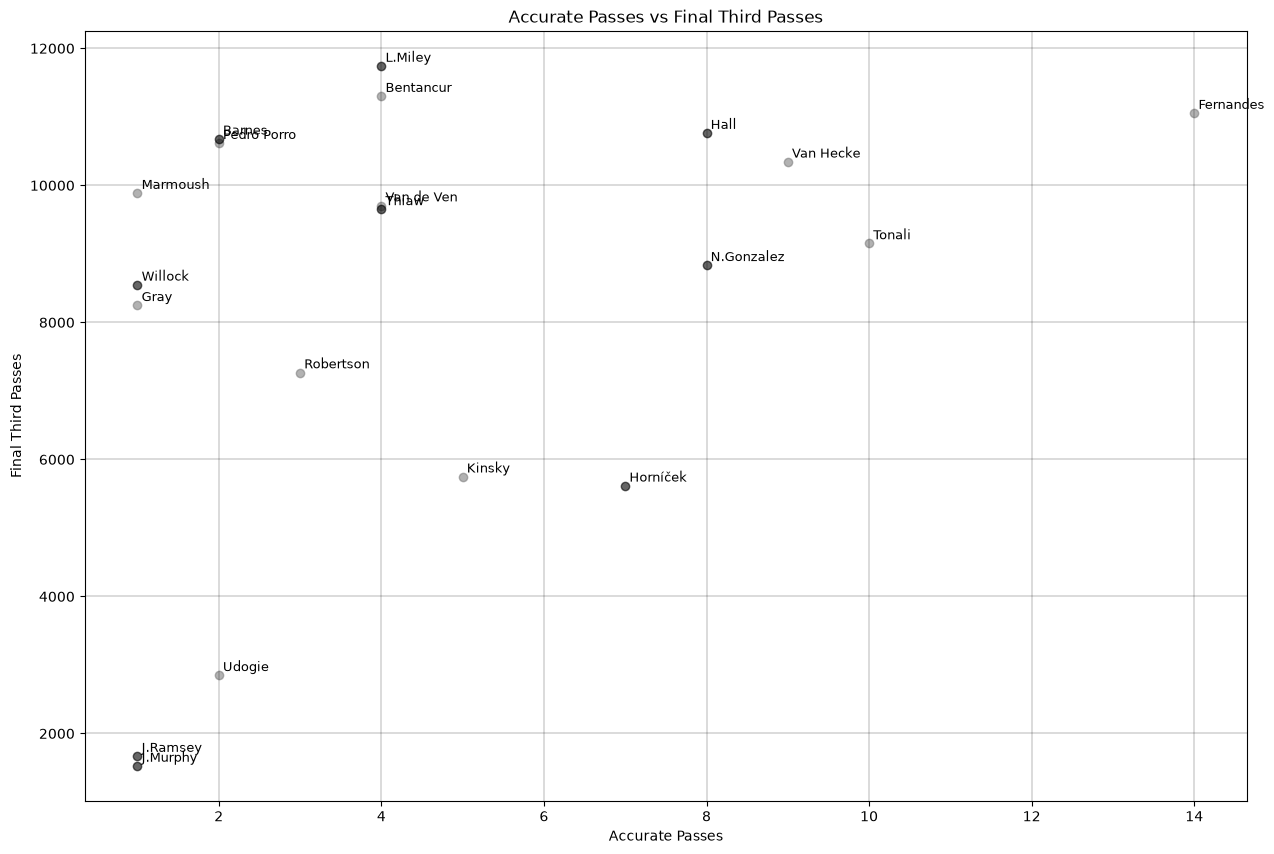

In [6]:
plot = match_plot(match, 'final_third_passes', 'distance_covered')